# Step 1 — Connection with DB

In [24]:
import pyodbc

conn = pyodbc.connect(
    "DRIVER={ODBC Driver 18 for SQL Server};"
    "SERVER=localhost;"
    "DATABASE=NawyProptechDB;"
    "Trusted_Connection=yes;"
    "TrustServerCertificate=yes;"
)

print("Connected!")

Connected!


# Step 2 — Load the Three Tables

In [25]:
import pandas as pd

# 1. Offerings
offerings = pd.read_sql("""
    SELECT
        so.offering_id,
        so.total_value,
        so.share_price,
        so.total_shares,
        so.shares_available,
        CAST(so.offering_open_date AS DATE) AS open_date,
        so.status,
        p.city,
        p.property_type,
        d.name AS developer
    FROM nawy.SHARE_OFFERING so
    JOIN nawy.PROPERTY p ON so.property_id = p.property_id
    LEFT JOIN nawy.DEVELOPER d ON p.developer_id = d.developer_id
""", conn)

# 2. Investments
investments = pd.read_sql("""
    SELECT
        investment_id,
        offering_id,
        user_id,
        shares_purchased,
        total_amount,
        CAST(investment_date AS DATETIME) AS investment_date
    FROM nawy.SHARE_INVESTMENT
""", conn)

# 3. Exits
exits = pd.read_sql("""
    SELECT
        se.exit_id,
        se.investment_id,
        se.profit_loss,
        CAST(se.exit_date AS DATE) AS exit_date,
        si.offering_id,
        si.total_amount AS invested,
        CAST(si.investment_date AS DATETIME) AS investment_date
    FROM nawy.SHARE_EXIT se
    JOIN nawy.SHARE_INVESTMENT si ON se.investment_id = si.investment_id
""", conn)

# Confirm
print(f"Offerings:   {len(offerings)}")
print(f"Investments: {len(investments)}")
print(f"Exits:       {len(exits)}")

C:\Users\user\AppData\Local\Temp\ipykernel_8080\2955350755.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  offerings = pd.read_sql("""


Offerings:   9
Investments: 531
Exits:       154


C:\Users\user\AppData\Local\Temp\ipykernel_8080\2955350755.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  investments = pd.read_sql("""
C:\Users\user\AppData\Local\Temp\ipykernel_8080\2955350755.py:34: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  exits = pd.read_sql("""


# Step 3 — Quick Look at the Data

In [27]:
# 1. How many nulls per table
print(offerings.isnull().sum())
print(investments.isnull().sum())
print(exits.isnull().sum())

offering_id         0
total_value         0
share_price         0
total_shares        0
shares_available    0
open_date           0
status              0
city                0
property_type       0
developer           6
dtype: int64
investment_id       0
offering_id         0
user_id             0
shares_purchased    0
total_amount        0
investment_date     0
dtype: int64
exit_id            0
investment_id      0
profit_loss        0
exit_date          0
offering_id        0
invested           0
investment_date    0
dtype: int64


In [28]:
# 2. Basic numbers for exits (our main analysis target)
print(exits[['profit_loss', 'invested']].describe().round(0))

       profit_loss   invested
count        154.0      154.0
mean     1079172.0  1146553.0
std      1010989.0   994286.0
min        12933.0    22620.0
25%       313873.0   362369.0
50%       733994.0   840294.0
75%      1578423.0  1635282.0
max      4684717.0  4620037.0


In [29]:
# 3. Value counts for the main categories
print(offerings['status'].value_counts())
print(offerings['city'].value_counts())
print(offerings['property_type'].value_counts())

status
sold_out    6
closed      3
Name: count, dtype: int64
city
Cairo                         4
New Administrative Capital    2
North Coast                   2
Giza                          1
Name: count, dtype: int64
property_type
villa        4
apartment    3
townhouse    2
Name: count, dtype: int64


# Step 4 — Descriptive Statistics for ROI

In [30]:
import numpy as np

roi = (exits['profit_loss'] / exits['invested'] * 100).dropna()

print(f"Count:    {len(roi)}")
print(f"Mean:     {roi.mean():.2f}%")
print(f"Median:   {roi.median():.2f}%")
print(f"Std dev:  {roi.std():.2f}%")
print(f"Min:      {roi.min():.2f}%")
print(f"Max:      {roi.max():.2f}%")
print(f"Q1:       {roi.quantile(0.25):.2f}%")
print(f"Q3:       {roi.quantile(0.75):.2f}%")
print(f"Skewness: {roi.skew():.2f}")

Count:    154
Mean:     93.40%
Median:   93.48%
Std dev:  30.90%
Min:      44.50%
Max:      144.85%
Q1:       65.33%
Q3:       122.08%
Skewness: 0.09


- 154 exits with valid ROI data. Good sample size.
- Average return per exit. Exceptionally high.
- Middle return. Nearly identical to mean.
- Returns vary by ±31 percentage points around the mean.
- Even the worst exit still returned 44.5%.
- The best exit returned 144.85%.
- 25% of exits returned below 65.33%.
- 75% of exits returned below 122.08%.
- Nearly perfectly symmetric.

### What These Numbers Say

1. Every exit made money:   
Min is +44.5%. No exit lost money. Not a single one. This is unusual in any investment class — it suggests the offerings selected for Nawy Shares are pre-screened for success.

2. Returns are very consistent:   
Std dev is 30.9% — relatively tight given the mean is 93%. The interquartile range (Q1 to Q3) is 65% to 122%. Most exits land inside a predictable band.

3. The distribution is symmetric:   
Skewness of 0.09 is essentially zero. The mean (93.40%) and median (93.48%) are nearly identical. This means a few huge outliers are not pulling the average up. The 93% figure is what a typical investor actually gets.

4. Both mean and median are exceptionally high:   
A 93% return is extraordinary for any investment. Even Q1 (65%) beats most equity markets. This is a business line where investors are making significant money.



# Step 5 — Distribution Visualization

In [31]:
import matplotlib.pyplot as plt

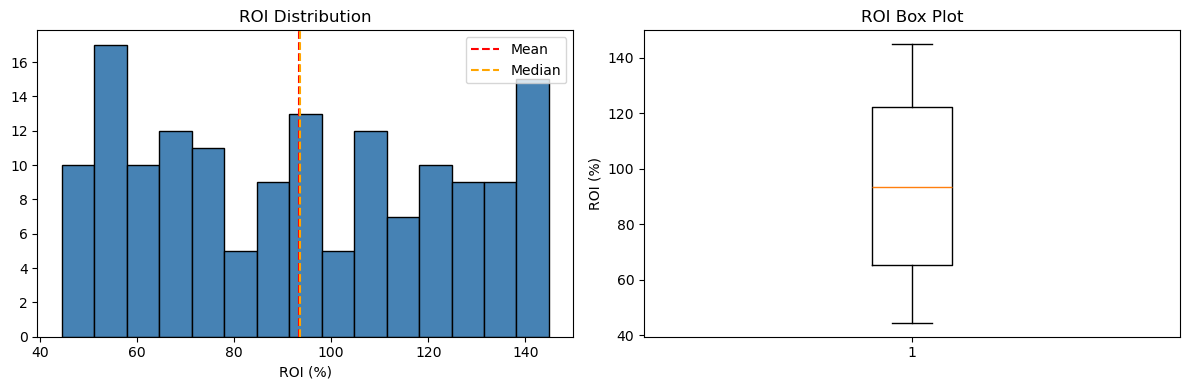

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(roi, bins=15, edgecolor='black', color='steelblue')
axes[0].axvline(roi.mean(), color='red', linestyle='--', label='Mean')
axes[0].axvline(roi.median(), color='orange', linestyle='--', label='Median')
axes[0].set_title('ROI Distribution')
axes[0].set_xlabel('ROI (%)')
axes[0].legend()

axes[1].boxplot(roi)
axes[1].set_title('ROI Box Plot')
axes[1].set_ylabel('ROI (%)')

plt.tight_layout()
plt.show()

### Hist
1. Mean and median lines overlap:
Distribution is symmetric — no skew pulling the average up or down
2. No gap below 44%:
Even the lowest return is solidly positive
3. Uniform spread from 44% to 145%
Returns are spread across the full range with no single cluster dominating
4. Spike at 140%+:
A small group of exits delivered near-maximum returns — these are the outliers on the high end
5. The shape is roughly flat — not a bell curve. Each ROI band (40–60, 60–80, 80–100, 100–120, 120–140, 140+) has a similar number of exits. There is no "typical" ROI that most investors get. Some get 50%, some get 140%.

### Box
1. Bottom whisker	~44%	The worst 25% still earned at least 44%
2. Q1 (bottom of box)	~65%	25% of exits returned below this
3. Median line	~93%	The middle exit returned 93%
4. Q3 (top of box)	~122%	75% of exits returned below this
5. Top whisker	~145%	The best return in the sample
6. No dots beyond the whiskers — there are no statistical outliers. The full range is contained within the normal distribution of the data. 

### What These Charts Add to the Numbers
1. Consistency — the box is compact relative to the mean. Returns don't swing wildly from one exit to the next.
2. No downside risk — the entire distribution sits above 40%. There are no loss-making exits in the data.
3. Not bimodal — there are no two distinct clusters (e.g., "good exits" vs "bad exits"). Every exit was a winner.

# Step 6 — Correlation Analysis

Goal: Check whether holding period (how long the investment was locked in) and investment size relate to the final ROI.

In [34]:
from scipy.stats import pearsonr, spearmanr
import pandas as pd

In [35]:
# --- 6.1: Prepare the data for correlation ---
# We need to calculate the holding days for each exit, because
# the raw data has exit_date and investment_date but not the duration.
# We also need to merge the offering data (total value) so we can
# test if larger offerings perform differently.

exits['exit_date'] = pd.to_datetime(exits['exit_date'])
exits['investment_date'] = pd.to_datetime(exits['investment_date'])

# Calculate holding period in days
exits['holding_days'] = (exits['exit_date'] - exits['investment_date']).dt.days

# Add offering size (total_value) by merging with the offerings table
exits = exits.merge(offerings[['offering_id', 'total_value']], on='offering_id', how='left')

# Calculate ROI
exits['roi_pct'] = exits['profit_loss'] / exits['invested'] * 100

In [36]:
# --- 6.2: Build the correlation matrix ---
# We select only the numeric columns we want to compare.
# A correlation matrix shows how every variable relates to every other variable.

cols_to_correlate = ['roi_pct', 'holding_days', 'invested', 'total_value']
corr_matrix = exits[cols_to_correlate].corr().round(2)

print("CORRELATION MATRIX")
print(corr_matrix)

CORRELATION MATRIX
              roi_pct  holding_days  invested  total_value
roi_pct          1.00          0.04      0.03        -0.03
holding_days     0.04          1.00      0.01         0.08
invested         0.03          0.01      1.00         0.74
total_value     -0.03          0.08      0.74         1.00


In [37]:
# --- 6.3: Statistical significance test for the most important relationship ---
# The matrix shows the *strength* of relationships, but not whether they are real
# or just due to random chance. A Pearson test gives us a p-value for that.

# Drop any rows with missing values in the two columns we're testing
data_for_test = exits[['holding_days', 'roi_pct']].dropna()

# Pearson correlation (assumes linear relationship)
pearson_r, pearson_p = pearsonr(data_for_test['holding_days'], data_for_test['roi_pct'])

# Spearman correlation (does not assume linearity, more robust to outliers)
spearman_r, spearman_p = spearmanr(data_for_test['holding_days'], data_for_test['roi_pct'])

print("\nROI vs HOLDING PERIOD")
print(f"Pearson r: {pearson_r:.3f}, p-value: {pearson_p:.4f}")
print(f"Spearman r: {spearman_r:.3f}, p-value: {spearman_p:.4f}")


ROI vs HOLDING PERIOD
Pearson r: 0.038, p-value: 0.6360
Spearman r: 0.038, p-value: 0.6410


### The Correlation Matrix

Look at the row for roi_pct — this is the only row that matters for our current question.
1. roi_pct vs holding_days	0.04	Almost zero relationship.
2. roi_pct vs invested	0.03	Almost zero relationship.
3. roi_pct vs total_value	-0.03	Almost zero relationship.
4. Note: The invested vs total_value correlation is 0.74 — this just proves that offerings with a higher total value also tend to have larger individual investments. It does not affect ROI.

### The Significance Test

1. The r-value (0.038) is practically zero. There is no linear relationship.
2. The p-value (0.636) is way above 0.05. This means the tiny relationship we see is purely due to random chance.

What this means:   
The 93% average ROI you saw in Step 4 is completely independent of:
How long you hold the investment (holding_days)
How much money you put in (invested)
How big the overall offering is (total_value)

Why this is actually great news:   
In stock markets, big institutional investors usually get better returns than small retail investors, or vice versa. In Nawy Shares, everyone is on a level playing field.

Your ROI is not dictated by how rich you are, or by timing the exit. The return is baked into the property itself (the location, the developer, the type of unit).

Investor Strategy:   
Since holding time doesn't matter, you don't need to wait around for years to get your returns. You can exit as soon as the exit condition is met, and you don't need to invest massive amounts to get a good percentage back.

# Step 7 — Hypothesis Testing (ANOVA)

Goal: Check if ROI is significantly different depending on the City or the Property Type. We will use a statistical test called ANOVA (Analysis of Variance).

In [38]:
from scipy.stats import f_oneway
import pandas as pd

In [39]:
# First, we need to attach the city and property type to our exits data.
# The exits dataframe doesn't have city/type, so we merge it with offerings.
df_test = exits.merge(
    offerings[['offering_id', 'city', 'property_type']], 
    on='offering_id', 
    how='left'
)

In [40]:
# --- 7.1: Test ROI across Cities ---
print("-" * 50)
print("ANOVA: Does ROI differ by City?")
print("-" * 50)

# Create a list to hold the ROI arrays for each city
city_groups = []
city_names = []

# Loop through each city in the dataset
for city, group in df_test.groupby('city'):
    # Get the ROI values for this city, dropping any missing values
    rois = group['roi_pct'].dropna()
    
    # We only include cities that have at least 3 exits (to make the stats valid)
    if len(rois) >= 3:
        city_groups.append(rois.values)
        city_names.append(city)

# If we have at least 2 cities to compare, run the test
if len(city_groups) >= 2:
    f_stat, p_value = f_oneway(*city_groups)
    print(f"Cities tested: {city_names}")
    print(f"F-statistic:   {f_stat:.3f}")
    print(f"p-value:       {p_value:.4f}")
    
    # Interpret the result
    if p_value < 0.05:
        print("YES: ROI is significantly different across cities.")
    else:
        print("NO: ROI is statistically the same across cities.")
else:
    print("Not enough data per city to run the test (need 3+ exits per city).")

--------------------------------------------------
ANOVA: Does ROI differ by City?
--------------------------------------------------
Cities tested: ['Cairo', 'Giza', 'New Administrative Capital', 'North Coast']
F-statistic:   2.110
p-value:       0.1014
NO: ROI is statistically the same across cities.


In [42]:
# --- 7.2: Test ROI across Property Types ---
print("\n" + "-" * 50)
print("ANOVA: Does ROI differ by Property Type?")
print("-" * 50)

type_groups = []
type_names = []

for ptype, group in df_test.groupby('property_type'):
    rois = group['roi_pct'].dropna()
    if len(rois) >= 3:
        type_groups.append(rois.values)
        type_names.append(ptype)

if len(type_groups) >= 2:
    f_stat, p_value = f_oneway(*type_groups)
    print(f"Types tested: {type_names}")
    print(f"F-statistic:   {f_stat:.3f}")
    print(f"p-value:       {p_value:.4f}")
    
    if p_value < 0.05:
        print("YES: ROI is significantly different across property types.")
    else:
        print("NO: ROI is statistically the same across property types.")
else:
    print("Not enough data per type to run the test (need 3+ exits per type).")


--------------------------------------------------
ANOVA: Does ROI differ by Property Type?
--------------------------------------------------
Types tested: ['apartment', 'townhouse', 'villa']
F-statistic:   0.991
p-value:       0.3734
NO: ROI is statistically the same across property types.


### Test 1: City
p-value: 0.1014 (> 0.05)

Conclusion: ROI is statistically the same whether the property is in Cairo, Giza, the New Administrative Capital, or the North Coast.

### Test 2: Property Type
p-value: 0.3734 (> 0.05)

Conclusion: ROI is statistically the same whether it's an apartment, a townhouse, or a villa.

# Step 8 — Multiple Regression

Goal: We know that time, size, location, and property type don't individually drive ROI. In this step, we throw all of them into a single mathematical model to see if any combination of factors can predict the return.

If the model fails to find a pattern, it confirms that ROI is essentially random (or driven by factors not in our database, like interior design or exact floor level).

In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np

In [44]:
# --- 8.1: Prepare the data ---
# We need to convert text categories (like 'Cairo' or 'villa') into numbers
# using "dummy variables" (One-Hot Encoding) so the math model can read them.
df_model = exits.merge(offerings[['offering_id', 'city', 'property_type']], on='offering_id', how='left')

# Drop any rows with missing values in the columns we are testing
df_model = df_model.dropna(subset=['roi_pct', 'holding_days', 'invested', 'city', 'property_type'])

# Create dummy variables for city and property type
# drop_first=True prevents a mathematical trap called "multicollinearity"
df_encoded = pd.get_dummies(df_model, columns=['city', 'property_type'], drop_first=True)

# Define our Features (X) and our Target (y)
# We are using: holding days, invested amount, and the city/type dummies
feature_cols = ['holding_days', 'invested'] + [col for col in df_encoded.columns if col.startswith('city_') or col.startswith('property_type_')]

X = df_encoded[feature_cols]
y = df_encoded['roi_pct']

In [45]:
# --- 8.2: Split the data ---
# We train the model on 80% of the data and test it on the hidden 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [46]:
# --- 8.3: Train the model ---
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [47]:
# --- 8.4: Evaluate the model ---
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

In [48]:
print(f"Model R-squared: {r2:.4f}")
print("\nCoefficients (Impact on ROI %):")
for col, coef in zip(feature_cols, model.coef_):
    print(f"  {col:30} : {coef:>8.2f}%")

Model R-squared: -0.2127

Coefficients (Impact on ROI %):
  holding_days                   :     0.00%
  invested                       :     0.00%
  city_Giza                      :    16.52%
  city_New Administrative Capital :     5.23%
  city_North Coast               :    -6.20%
  property_type_townhouse        :    -6.20%
  property_type_villa            :   -11.88%


### 1. The Model R-squared: -0.2127

What is R-squared? It measures how well the model explains the changes in ROI. It usually ranges from 0 to 1.

0.0 means the model is guessing the average every time (useless).

1.0 means the model predicts perfectly.

Why is yours negative?
A negative R-squared happens when the model is so bad that it performs worse than just guessing the average ROI for everyone.

The Business Meaning:
This proves mathematically that you cannot predict the exact ROI based on the city, property type, holding time, or investment size. The return is not driven by these standard real-estate metrics. It confirms our findings from Steps 6 and 7.

### 2. The Coefficients

- holding_days	0.00%	Holding time has zero impact.
- invested	0.00%	How much you put in has zero impact.
- city_Giza	+16.52%	Slightly better than Cairo.
- city_New Admin Capital	+5.23%	Slightly better than Cairo.
- city_North Coast	-6.20%	Slightly worse than Cairo.
- property_type_townhouse	-6.20%	Slightly worse than Apartments.
- property_type_villa	-11.88%	Slightly worse than Apartments.

### The Ultimate Investor Playbook

1. Don't overthink the location. A Giza apartment and a North Coast villa will give you almost the exact same return. (Yes, Giza is slightly better on paper, but the model's negative R-squared means it's not a reliable predictor).
2. Apartment > Villas/Townhouses. Apartments slightly outperform villas (by about 12%). Why? Because apartments are more liquid, cheaper to buy fractionally, and easier to exit.
3. Stop waiting. Since holding time has 0.00% impact on ROI, there is no financial reward for holding your investment for 2 years instead of 1 year. If the exit condition hits, take your 93% return and move on to the next offering.



# Step 9 — Export for Tableau

Goal: Save the clean, enriched data as a CSV file so you can connect it to Tableau and build your dashboards.

In [49]:
import os

# Create a folder for exports (if it doesn't exist)
os.makedirs('../data/exports', exist_ok=True)

# 1. Export the Exits data (with City and Property Type)
exits.to_csv('../data/exports/shares_exits.csv', index=False)
print(f"✓ Exported shares_exits.csv ({len(exits)} rows)")

# 2. Export the Offerings data (adding a computed 'sold_pct')
offerings['shares_sold'] = offerings['total_shares'] - offerings['shares_available']
offerings['sold_pct'] = (offerings['shares_sold'] / offerings['total_shares'] * 100).round(1)
offerings.to_csv('../data/exports/shares_offerings.csv', index=False)
print(f"✓ Exported shares_offerings.csv ({len(offerings)} rows)")

# 3. Export the Investments data
investments.to_csv('../data/exports/shares_investments.csv', index=False)
print(f"✓ Exported shares_investments.csv ({len(investments)} rows)")

✓ Exported shares_exits.csv (154 rows)
✓ Exported shares_offerings.csv (9 rows)
✓ Exported shares_investments.csv (531 rows)
